In [1]:
import ptwt
import librosa
import torch
import random
import time


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
)
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import Dataset, DataLoader

In [2]:
EPOCHS = 100
BATCH_SIZE = 32
SEED = 42
FREQ_MASK_MAX = 4
TIME_MASK_MAX = 20
N_MASKS = 2

if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Success: Mac GPU (MPS) is available!")
else:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)

In [ ]:
def load_split(name):
    X = np.load(f"../Data/{name}_features.npy", mmap_mode="r")
    meta = pd.read_csv(f"../Data/{name}_meta.csv")

    X = np.asarray(X, dtype=np.float32).reshape(X.shape[0], -1, X.shape[-1])
    y = meta["is_bonafide"].to_numpy().astype(np.int64)

    return X, y, meta

In [4]:
t0 = time.time()
X_train, y_train, train_meta = load_split("train")
X_dev, y_dev, dev_meta = load_split("dev")
X_eval, y_eval, eval_meta = load_split("eval")
print(f"{time.time() - t0:.1f}s | train {X_train.shape} | dev {X_dev.shape} | eval {X_eval.shape}")

7.8s | train (25380, 40, 401) | dev (24844, 40, 401) | eval (71237, 40, 401)


In [5]:
row_mean = X_train.mean(axis=(0, 2), keepdims=True)
row_std = X_train.std(axis=(0, 2), keepdims=True) + 1e-6

X_train = (X_train - row_mean) / row_std
X_dev = (X_dev - row_mean) / row_std
X_eval = (X_eval - row_mean) / row_std

In [6]:
class AudioFeaturesDataset(Dataset):
    def __init__(self, X, y, train=False):
        self.X = torch.from_numpy(X).unsqueeze(1)
        self.y = torch.from_numpy(y)
        self.train = train

    def __len__(self):
        return len(self.y)

    def spec_augment(self, x):
        _, Fdim, Tdim = x.shape
        x = x.clone()
        for _ in range(N_MASKS):
            f = random.randint(0, FREQ_MASK_MAX)
            f0 = random.randint(0, max(0, Fdim - f))
            x[:, f0:f0 + f, :] = 0.0
            t = random.randint(0, TIME_MASK_MAX)
            t0 = random.randint(0, max(0, Tdim - t))
            x[:, :, t0:t0 + t] = 0.0
        return x

    def __getitem__(self, idx):
        x = self.X[idx]
        if self.train:
            x = self.spec_augment(x)
        return x, self.y[idx]

In [7]:
train_dataset = AudioFeaturesDataset(X_train, y_train, train=True)
dev_dataset = AudioFeaturesDataset(X_dev, y_dev)
eval_dataset = AudioFeaturesDataset(X_eval, y_eval)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

eval_loader = DataLoader(
    eval_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

In [8]:
def conv_block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
    )


class AverageCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            conv_block(1, 32),
            conv_block(32, 32),
            nn.AvgPool2d(kernel_size=2),

            conv_block(32, 64),
            conv_block(64, 64),
            nn.AvgPool2d(kernel_size=2),

            conv_block(64, 128),
            conv_block(128, 128),
            nn.AvgPool2d(kernel_size=2),

            conv_block(128, 256),
            conv_block(256, 256),
            nn.Dropout2d(0.1),
        )

        self.classifier = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        x = self.features(x)
        x = x.mean(dim=2)
        x = torch.cat([x.mean(dim=2), x.std(dim=2)], dim=1)
        return self.classifier(x)

In [9]:
num_bonafide = int(y_train.sum())
num_spoof = int(len(y_train) - num_bonafide)

print(num_bonafide, num_spoof)

total = num_bonafide + num_spoof

weight_bonafide = total / (2 * num_bonafide)
weight_spoof = total / (2 * num_spoof)

class_weights = torch.tensor(
    [weight_spoof, weight_bonafide],
    dtype=torch.float32
).to(device)

2580 22800


In [10]:
class EarlyStopper:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.min_validation_metric = float('inf')

    def early_stop(self, validation_metric):
        if validation_metric < self.min_validation_metric - self.min_delta:
            self.min_validation_metric = validation_metric
            self.counter = 0
        else:
            self.counter += 1
        return self.counter >= self.patience

In [11]:
def calculate_eer(labels, scores):
    fpr, tpr, thresholds = roc_curve(labels, scores, pos_label=1)
    fnr = 1 - tpr
    diff = fpr - fnr
    i = int(np.argmax(diff >= 0))
    if i == 0 or diff[i] == diff[i - 1]:
        eer = (fpr[i] + fnr[i]) / 2
    else:
        t = -diff[i - 1] / (diff[i] - diff[i - 1])
        eer = fpr[i - 1] + t * (fpr[i] - fpr[i - 1])
    return float(eer), float(thresholds[i])


def llr_score(logits):
    return logits[:, 1] - logits[:, 0]

In [12]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    total = 0
    all_labels = []
    all_scores = []

    for X, y in loader:

        X = X.to(device)
        y = y.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(X)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X.size(0)
        total += y.size(0)
        all_labels.append(y.detach().cpu())
        all_scores.append(llr_score(logits).detach().cpu())

    epoch_loss = running_loss / total
    epoch_eer, _ = calculate_eer(
        torch.cat(all_labels).numpy(),
        torch.cat(all_scores).numpy()
    )

    return epoch_loss, epoch_eer

In [ ]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    total = 0

    all_labels = []
    all_scores = []

    for X, y in loader:
        X = X.to(device)
        y = y.to(device)

        logits = model(X)
        loss = criterion(logits, y)
        running_loss += loss.item() * X.size(0)
        total += y.size(0)

        all_labels.append(y.cpu())
        all_scores.append(llr_score(logits).cpu())

    all_labels = torch.cat(all_labels).numpy()
    all_scores = torch.cat(all_scores).numpy()

    epoch_loss = running_loss / total
    eer, threshold = calculate_eer(all_labels, all_scores)
    all_predictions = (all_scores >= threshold).astype(int)

    return (
        epoch_loss,
        eer,
        threshold,
        all_labels,
        all_predictions,
        all_scores,
    )

In [14]:
def run_model(model, criterion, optimizer, scheduler):
    history = {
        "train_loss": [],
        "train_eer": [],
        "dev_loss": [],
        "dev_eer": [],
        "lr": [],
    }

    best_dev_eer = float("inf")
    best_model_state = None
    best_model_status = {}

    early_stopper = EarlyStopper(patience=15)
    for epoch in range(EPOCHS):
        train_loss, train_eer = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        dev_loss, dev_eer, _, _, _, _ = evaluate(
            model,
            dev_loader,
            criterion,
            device
        )

        scheduler.step(dev_eer)

        history["train_loss"].append(train_loss)
        history["train_eer"].append(train_eer)

        history["dev_loss"].append(dev_loss)
        history["dev_eer"].append(dev_eer)
        history["lr"].append(optimizer.param_groups[0]['lr'])

        if dev_eer < best_dev_eer:
            best_dev_eer = dev_eer
            best_model_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            best_model_status = {
                "epoch": epoch+1,
                "train_loss": train_loss,
                "train_eer": train_eer,
                "dev_loss": dev_loss,
                "best_dev_eer": best_dev_eer
            }

        if early_stopper.early_stop(dev_eer):
            print("Early Stopping...")
            break

        print(
            f"Epoch {epoch + 1:02d}/{EPOCHS} | "
            f"LR: {history['lr'][-1]:.6f} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train EER: {train_eer:.4f} | "
            f"Dev Loss: {dev_loss:.4f} | "
            f"Dev EER: {dev_eer:.4f}"
        )

    print(f"Best Model: {best_model_status}")

    return history, best_model_state

In [15]:
def setup_model():
    model = AverageCNN().to(device)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    scheduler = ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.1,
        patience=5,
        threshold=1e-4,
        min_lr=1e-6
    )

    history, best_model_state = run_model(model, criterion, optimizer, scheduler)
    return model, criterion, history, best_model_state

In [16]:
results = []

model, criterion, history, best_model_state = setup_model()

model.load_state_dict(best_model_state)
model.to(device)
model.eval()

(
    eval_loss,
    eer,
    eer_threshold,
    eval_labels,
    eval_predictions,
    eval_scores,
) = evaluate(model, eval_loader, criterion, device)

accuracy = accuracy_score(eval_labels, eval_predictions)
precision = precision_score(eval_labels, eval_predictions, pos_label=1, zero_division=0)
recall_bonafide = recall_score(eval_labels, eval_predictions, pos_label=1, zero_division=0)
recall_spoof = recall_score(eval_labels, eval_predictions, pos_label=0, zero_division=0)
f1 = f1_score(eval_labels, eval_predictions, pos_label=1, zero_division=0)

fpr, tpr, thresholds = roc_curve(eval_labels, eval_scores, pos_label=1)
roc_auc = auc(fpr, tpr)

results.append({
    "eval_loss": eval_loss,
    "eer": eer,
    "eer_threshold": eer_threshold,
    "accuracy": accuracy,
    "precision": precision,
    "recall_bonafide": recall_bonafide,
    "recall_spoof": recall_spoof,
    "f1_score": f1,
    "roc_auc": roc_auc
})

results_df = pd.DataFrame(results)
results_df.to_csv("average_results.csv", index=False)
print("Resultados salvos com sucesso em 'average_results.csv'!")

Epoch 01/100 | LR: 0.000100 | Train Loss: 0.1729 | Train EER: 0.0651 | Dev Loss: 0.0198 | Dev EER: 0.0100
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.0473 | Train EER: 0.0169 | Dev Loss: 0.0214 | Dev EER: 0.0083
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0315 | Train EER: 0.0108 | Dev Loss: 0.0067 | Dev EER: 0.0043
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0292 | Train EER: 0.0109 | Dev Loss: 0.1282 | Dev EER: 0.0075
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0189 | Train EER: 0.0062 | Dev Loss: 0.0239 | Dev EER: 0.0052
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0202 | Train EER: 0.0068 | Dev Loss: 0.0116 | Dev EER: 0.0063
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0141 | Train EER: 0.0043 | Dev Loss: 0.0054 | Dev EER: 0.0035
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0128 | Train EER: 0.0046 | Dev Loss: 0.0073 | Dev EER: 0.0047
Epoch 09/100 | LR: 0.000100 | Train Loss: 0.0145 | Train EER: 0.0043 | Dev Loss: 0.0227 | Dev EER: 0.0070
Epoch 10/100 | LR: 0.000100 | Train Loss: 0.01

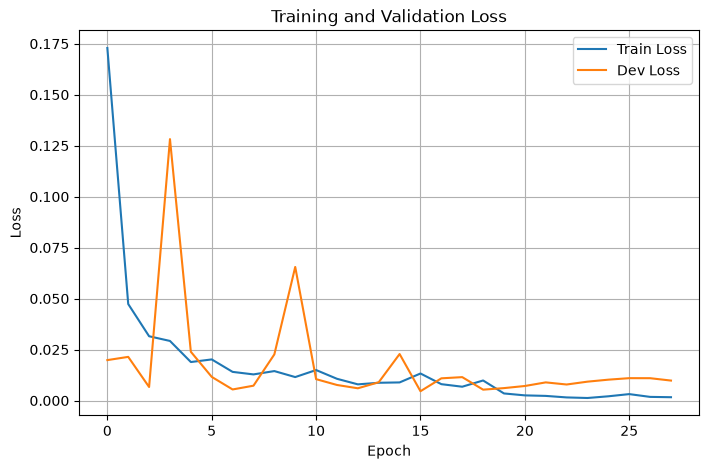

In [17]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["dev_loss"], label="Dev Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()


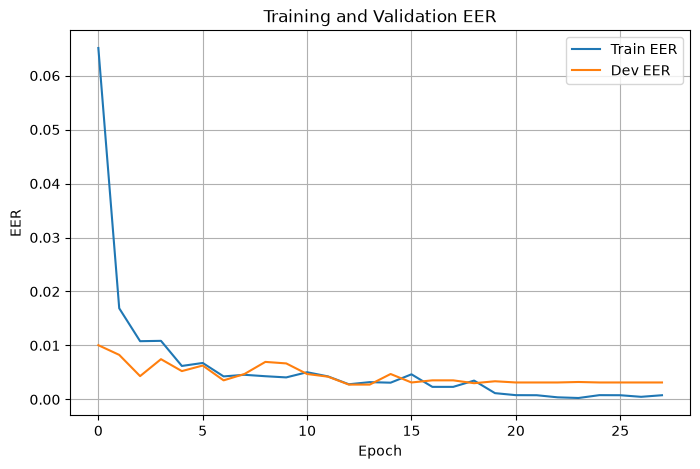

In [20]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_eer"], label="Train EER")
plt.plot(history["dev_eer"], label="Dev EER")
plt.xlabel("Epoch")
plt.ylabel("EER")
plt.title("Training and Validation EER")
plt.legend()
plt.grid()
plt.show()


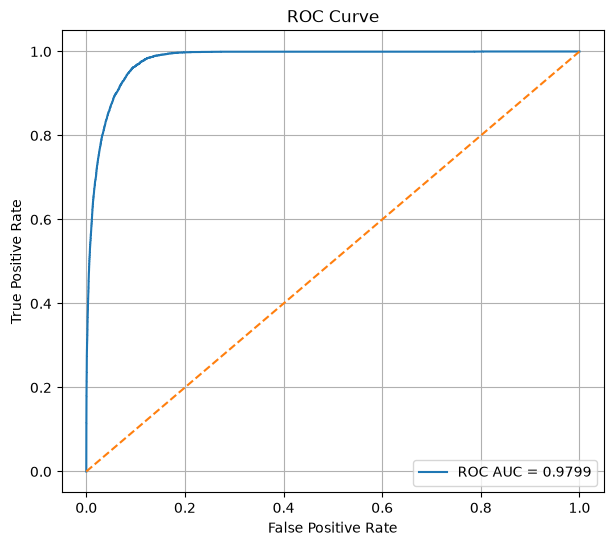

In [21]:
plt.figure(figsize=(7, 6))
plt.plot(
    fpr,
    tpr,
    label=f"ROC AUC = {roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()